In [ ]:
print("QoS-Aware Intelligent Task Scheduling Using Federated Learning for Edge Computing")
print("Our project is starting!")

QoS-Aware Intelligent Task Scheduling Using Federated Learning for Edge Computing
Our project is starting!


In [ ]:
import random

# Create 10 tasks
random.seed(42)

tasks = []

for i in range(10):
    task = {
        "task_id": i + 1,
        "execution_time": random.randint(1, 10),
        "priority": random.randint(1, 3),
        "deadline": random.randint(5, 15)
    }

    tasks.append(task)

# Display all tasks
for task in tasks:
    print(task)

{'task_id': 1, 'execution_time': 2, 'priority': 1, 'deadline': 9}
{'task_id': 2, 'execution_time': 4, 'priority': 1, 'deadline': 7}
{'task_id': 3, 'execution_time': 2, 'priority': 3, 'deadline': 13}
{'task_id': 4, 'execution_time': 2, 'priority': 3, 'deadline': 11}
{'task_id': 5, 'execution_time': 1, 'priority': 1, 'deadline': 6}
{'task_id': 6, 'execution_time': 4, 'priority': 1, 'deadline': 13}
{'task_id': 7, 'execution_time': 10, 'priority': 1, 'deadline': 13}
{'task_id': 8, 'execution_time': 4, 'priority': 3, 'deadline': 15}
{'task_id': 9, 'execution_time': 9, 'priority': 2, 'deadline': 8}
{'task_id': 10, 'execution_time': 8, 'priority': 3, 'deadline': 9}


In [ ]:
# Create three edge nodes

edge_nodes = [
    {"node_id": 1, "speed": 2},
    {"node_id": 2, "speed": 3},
    {"node_id": 3, "speed": 5}
]

# Display the edge nodes
for node in edge_nodes:
    print(node)

{'node_id': 1, 'speed': 2}
{'node_id': 2, 'speed': 3}
{'node_id': 3, 'speed': 5}


In [ ]:
# Calculate execution time for every task on every edge node

for task in tasks:
    print(f"\nTask {task['task_id']}")

    for node in edge_nodes:
        execution_time = task["execution_time"] / node["speed"]

        print(
            f"  Node {node['node_id']}: "
            f"{execution_time:.2f} time units"
        )


Task 1
  Node 1: 1.00 time units
  Node 2: 0.67 time units
  Node 3: 0.40 time units

Task 2
  Node 1: 2.00 time units
  Node 2: 1.33 time units
  Node 3: 0.80 time units

Task 3
  Node 1: 1.00 time units
  Node 2: 0.67 time units
  Node 3: 0.40 time units

Task 4
  Node 1: 1.00 time units
  Node 2: 0.67 time units
  Node 3: 0.40 time units

Task 5
  Node 1: 0.50 time units
  Node 2: 0.33 time units
  Node 3: 0.20 time units

Task 6
  Node 1: 2.00 time units
  Node 2: 1.33 time units
  Node 3: 0.80 time units

Task 7
  Node 1: 5.00 time units
  Node 2: 3.33 time units
  Node 3: 2.00 time units

Task 8
  Node 1: 2.00 time units
  Node 2: 1.33 time units
  Node 3: 0.80 time units

Task 9
  Node 1: 4.50 time units
  Node 2: 3.00 time units
  Node 3: 1.80 time units

Task 10
  Node 1: 4.00 time units
  Node 2: 2.67 time units
  Node 3: 1.60 time units


In [ ]:
# FIFO scheduling baseline

node_available_time = {node["node_id"]: 0 for node in edge_nodes}
fifo_results = []

for task in tasks:
    best_node = None
    earliest_finish = float("inf")
    best_processing_time = 0

    # Find the node that can finish this task earliest
    for node in edge_nodes:
        processing_time = task["execution_time"] / node["speed"]
        finish_time = node_available_time[node["node_id"]] + processing_time

        if finish_time < earliest_finish:
            earliest_finish = finish_time
            best_node = node
            best_processing_time = processing_time

    # Assign the task to the selected node
    node_id = best_node["node_id"]
    node_available_time[node_id] = earliest_finish

    fifo_results.append({
        "task_id": task["task_id"],
        "node_id": node_id,
        "processing_time": round(best_processing_time, 2),
        "completion_time": round(earliest_finish, 2),
        "deadline": task["deadline"],
        "missed_deadline": earliest_finish > task["deadline"]
    })

# Display the schedule
for result in fifo_results:
    print(result)

{'task_id': 1, 'node_id': 3, 'processing_time': 0.4, 'completion_time': 0.4, 'deadline': 9, 'missed_deadline': False}
{'task_id': 2, 'node_id': 3, 'processing_time': 0.8, 'completion_time': 1.2, 'deadline': 7, 'missed_deadline': False}
{'task_id': 3, 'node_id': 2, 'processing_time': 0.67, 'completion_time': 0.67, 'deadline': 13, 'missed_deadline': False}
{'task_id': 4, 'node_id': 1, 'processing_time': 1.0, 'completion_time': 1.0, 'deadline': 11, 'missed_deadline': False}
{'task_id': 5, 'node_id': 2, 'processing_time': 0.33, 'completion_time': 1.0, 'deadline': 6, 'missed_deadline': False}
{'task_id': 6, 'node_id': 3, 'processing_time': 0.8, 'completion_time': 2.0, 'deadline': 13, 'missed_deadline': False}
{'task_id': 7, 'node_id': 3, 'processing_time': 2.0, 'completion_time': 4.0, 'deadline': 13, 'missed_deadline': False}
{'task_id': 8, 'node_id': 2, 'processing_time': 1.33, 'completion_time': 2.33, 'deadline': 15, 'missed_deadline': False}
{'task_id': 9, 'node_id': 2, 'processing_time'

In [ ]:
# Evaluate FIFO scheduling performance

total_tasks = len(fifo_results)

average_completion_time = sum(
    result["completion_time"] for result in fifo_results
) / total_tasks

deadline_misses = sum(
    result["missed_deadline"] for result in fifo_results
)

deadline_success_rate = (
    (total_tasks - deadline_misses) / total_tasks
) * 100

print("===== FIFO SCHEDULING RESULTS =====")
print("Total tasks:", total_tasks)
print("Average completion time:", round(average_completion_time, 2))
print("Deadline misses:", deadline_misses)
print("Deadline success rate:", round(deadline_success_rate, 2), "%")

===== FIFO SCHEDULING RESULTS =====
Total tasks: 10
Average completion time: 2.29
Deadline misses: 0
Deadline success rate: 100.0 %


In [ ]:
# QoS-aware scheduling baseline

qos_tasks = sorted(
    tasks,
    key=lambda task: (-task["priority"], task["deadline"])
)

qos_node_available_time = {
    node["node_id"]: 0 for node in edge_nodes
}

qos_results = []

for task in qos_tasks:
    best_node = None
    earliest_finish = float("inf")
    best_processing_time = 0

    for node in edge_nodes:
        processing_time = task["execution_time"] / node["speed"]
        finish_time = (
            qos_node_available_time[node["node_id"]] + processing_time
        )

        if finish_time < earliest_finish:
            earliest_finish = finish_time
            best_node = node
            best_processing_time = processing_time

    node_id = best_node["node_id"]
    qos_node_available_time[node_id] = earliest_finish

    qos_results.append({
        "task_id": task["task_id"],
        "priority": task["priority"],
        "node_id": node_id,
        "completion_time": round(earliest_finish, 2),
        "deadline": task["deadline"],
        "missed_deadline": earliest_finish > task["deadline"]
    })

# Display the QoS-aware schedule
for result in qos_results:
    print(result)

{'task_id': 10, 'priority': 3, 'node_id': 3, 'completion_time': 1.6, 'deadline': 9, 'missed_deadline': False}
{'task_id': 4, 'priority': 3, 'node_id': 2, 'completion_time': 0.67, 'deadline': 11, 'missed_deadline': False}
{'task_id': 3, 'priority': 3, 'node_id': 1, 'completion_time': 1.0, 'deadline': 13, 'missed_deadline': False}
{'task_id': 8, 'priority': 3, 'node_id': 2, 'completion_time': 2.0, 'deadline': 15, 'missed_deadline': False}
{'task_id': 9, 'priority': 2, 'node_id': 3, 'completion_time': 3.4, 'deadline': 8, 'missed_deadline': False}
{'task_id': 5, 'priority': 1, 'node_id': 1, 'completion_time': 1.5, 'deadline': 6, 'missed_deadline': False}
{'task_id': 2, 'priority': 1, 'node_id': 2, 'completion_time': 3.33, 'deadline': 7, 'missed_deadline': False}
{'task_id': 1, 'priority': 1, 'node_id': 1, 'completion_time': 2.5, 'deadline': 9, 'missed_deadline': False}
{'task_id': 6, 'priority': 1, 'node_id': 3, 'completion_time': 4.2, 'deadline': 13, 'missed_deadline': False}
{'task_id': 

In [ ]:
# Evaluate QoS-aware scheduling performance

qos_total_tasks = len(qos_results)

qos_average_completion_time = sum(
    result["completion_time"] for result in qos_results
) / qos_total_tasks

qos_deadline_misses = sum(
    result["missed_deadline"] for result in qos_results
)

qos_deadline_success_rate = (
    (qos_total_tasks - qos_deadline_misses) / qos_total_tasks
) * 100

print("===== QOS-AWARE SCHEDULING RESULTS =====")
print("Total tasks:", qos_total_tasks)
print(
    "Average completion time:",
    round(qos_average_completion_time, 2)
)
print("Deadline misses:", qos_deadline_misses)
print(
    "Deadline success rate:",
    round(qos_deadline_success_rate, 2),
    "%"
)

===== QOS-AWARE SCHEDULING RESULTS =====
Total tasks: 10
Average completion time: 2.64
Deadline misses: 0
Deadline success rate: 100.0 %


In [ ]:
# Compare both scheduling algorithms

import pandas as pd

comparison = pd.DataFrame([
    {
        "Algorithm": "FIFO",
        "Average Completion Time": round(average_completion_time, 2),
        "Deadline Misses": deadline_misses,
        "Deadline Success Rate (%)": round(deadline_success_rate, 2)
    },
    {
        "Algorithm": "QoS-Aware",
        "Average Completion Time": round(qos_average_completion_time, 2),
        "Deadline Misses": qos_deadline_misses,
        "Deadline Success Rate (%)": round(qos_deadline_success_rate, 2)
    }
])

comparison

,Algorithm,Average Completion Time,Deadline Misses,Deadline Success Rate (%)
0,FIFO,2.29,0,100.0
1,QoS-Aware,2.64,0,100.0


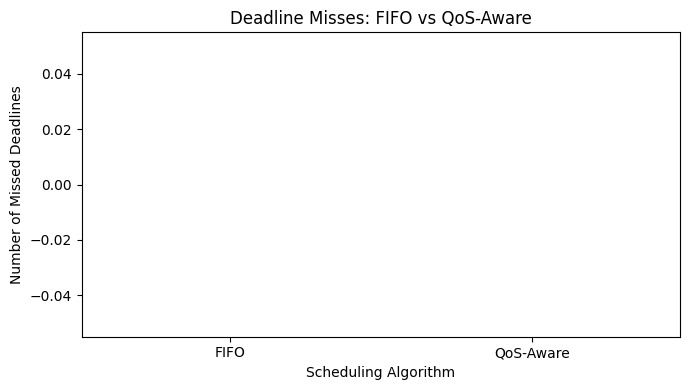

In [ ]:
import matplotlib.pyplot as plt

algorithms = ["FIFO", "QoS-Aware"]
misses = [deadline_misses, qos_deadline_misses]

plt.figure(figsize=(7, 4))
plt.bar(algorithms, misses)
plt.title("Deadline Misses: FIFO vs QoS-Aware")
plt.xlabel("Scheduling Algorithm")
plt.ylabel("Number of Missed Deadlines")
plt.tight_layout()
plt.show()

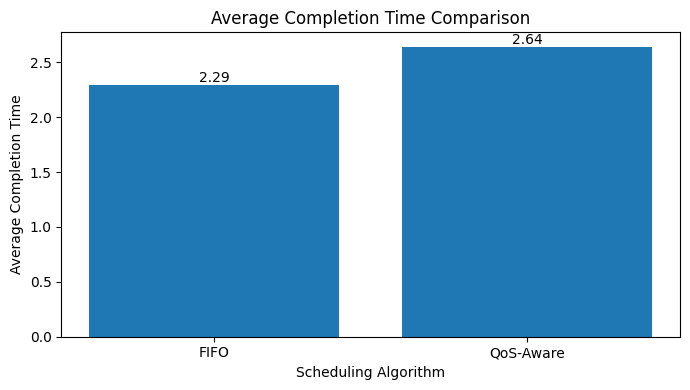

In [ ]:
import matplotlib.pyplot as plt

algorithms = ["FIFO", "QoS-Aware"]

completion_times = [
    average_completion_time,
    qos_average_completion_time
]

plt.figure(figsize=(7, 4))
bars = plt.bar(algorithms, completion_times)

plt.title("Average Completion Time Comparison")
plt.xlabel("Scheduling Algorithm")
plt.ylabel("Average Completion Time")

# Print each value above its bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [ ]:
# Compare completion times for individual tasks

fifo_completion = {
    result["task_id"]: result["completion_time"]
    for result in fifo_results
}

qos_completion = {
    result["task_id"]: result["completion_time"]
    for result in qos_results
}

task_comparison = pd.DataFrame([
    {
        "Task ID": task["task_id"],
        "FIFO Completion Time": fifo_completion[task["task_id"]],
        "QoS Completion Time": qos_completion[task["task_id"]]
    }
    for task in tasks
])

task_comparison

,Task ID,FIFO Completion Time,QoS Completion Time
0,1,0.40,2.50
1,2,1.20,3.33
2,3,0.67,1.00
3,4,1.00,0.67
4,5,1.00,1.50
5,6,2.00,4.20
6,7,4.00,6.20
7,8,2.33,2.00
8,9,5.33,3.40
9,10,5.00,1.60


In [ ]:
# Create a simple local model for each edge node

local_models = {
    1: [0.2, 0.4, 0.6],
    2: [0.3, 0.5, 0.7],
    3: [0.4, 0.6, 0.8]
}

print("Local models before federated averaging:")

for node_id, model in local_models.items():
    print(f"Edge Node {node_id}: {model}")

Local models before federated averaging:
Edge Node 1: [0.2, 0.4, 0.6]
Edge Node 2: [0.3, 0.5, 0.7]
Edge Node 3: [0.4, 0.6, 0.8]


In [ ]:
# Federated Averaging (FedAvg) demonstration

number_of_nodes = len(local_models)

global_model = []

for parameter_index in range(len(local_models[1])):
    parameter_sum = sum(
        model[parameter_index]
        for model in local_models.values()
    )

    average_parameter = parameter_sum / number_of_nodes
    global_model.append(round(average_parameter, 4))

print("Global model after federated averaging:")
print(global_model)

Global model after federated averaging:
[0.3, 0.5, 0.7]


In [ ]:
# Distribute the global model to all edge nodes

for node_id in local_models:
    local_models[node_id] = global_model.copy()

print("Local models after receiving the global model:")

for node_id, model in local_models.items():
    print(f"Edge Node {node_id}: {model}")

Local models after receiving the global model:
Edge Node 1: [0.3, 0.5, 0.7]
Edge Node 2: [0.3, 0.5, 0.7]
Edge Node 3: [0.3, 0.5, 0.7]


In [ ]:
# Prepare task features for scheduling analysis

task_features = pd.DataFrame([
    {
        "Task ID": task["task_id"],
        "Execution Work": task["execution_time"],
        "Priority": task["priority"],
        "Deadline": task["deadline"]
    }
    for task in tasks
])

print("Task features for scheduling:")
display(task_features)

Task features for scheduling:


,Task ID,Execution Work,Priority,Deadline
0,1,2,1,9
1,2,4,1,7
2,3,2,3,13
3,4,2,3,11
4,5,1,1,6
5,6,4,1,13
6,7,10,1,13
7,8,4,3,15
8,9,9,2,8
9,10,8,3,9


In [ ]:
# Compare deadline success rates

deadline_comparison = pd.DataFrame([
    {
        "Algorithm": "FIFO",
        "Tasks Meeting Deadline": total_tasks - deadline_misses,
        "Total Tasks": total_tasks,
        "Deadline Success Rate (%)": round(deadline_success_rate, 2)
    },
    {
        "Algorithm": "QoS-Aware",
        "Tasks Meeting Deadline": qos_total_tasks - qos_deadline_misses,
        "Total Tasks": qos_total_tasks,
        "Deadline Success Rate (%)": round(qos_deadline_success_rate, 2)
    }
])

display(deadline_comparison)

,Algorithm,Tasks Meeting Deadline,Total Tasks,Deadline Success Rate (%)
0,FIFO,10,10,100.0
1,QoS-Aware,10,10,100.0


In [ ]:
# Create a second workload with tighter deadlines

import random

random.seed(101)

challenging_tasks = []

for i in range(10):
    challenging_tasks.append({
        "task_id": i + 1,
        "execution_time": random.randint(5, 15),
        "priority": random.randint(1, 3),
        "deadline": random.randint(2, 8)
    })

print("Challenging workload:")
for task in challenging_tasks:
    print(task)

Challenging workload:
{'task_id': 1, 'execution_time': 14, 'priority': 1, 'deadline': 6}
{'task_id': 2, 'execution_time': 10, 'priority': 2, 'deadline': 2}
{'task_id': 3, 'execution_time': 15, 'priority': 3, 'deadline': 3}
{'task_id': 4, 'execution_time': 14, 'priority': 1, 'deadline': 4}
{'task_id': 5, 'execution_time': 12, 'priority': 3, 'deadline': 8}
{'task_id': 6, 'execution_time': 8, 'priority': 2, 'deadline': 5}
{'task_id': 7, 'execution_time': 6, 'priority': 2, 'deadline': 3}
{'task_id': 8, 'execution_time': 7, 'priority': 1, 'deadline': 5}
{'task_id': 9, 'execution_time': 13, 'priority': 2, 'deadline': 3}
{'task_id': 10, 'execution_time': 12, 'priority': 2, 'deadline': 3}


In [ ]:
# FIFO scheduling on the challenging workload

challenging_node_times = {
    node["node_id"]: 0 for node in edge_nodes
}

challenging_fifo_results = []

for task in challenging_tasks:
    best_node = None
    earliest_finish = float("inf")

    for node in edge_nodes:
        processing_time = task["execution_time"] / node["speed"]
        finish_time = (
            challenging_node_times[node["node_id"]] + processing_time
        )

        if finish_time < earliest_finish:
            earliest_finish = finish_time
            best_node = node

    node_id = best_node["node_id"]
    challenging_node_times[node_id] = earliest_finish

    challenging_fifo_results.append({
        "task_id": task["task_id"],
        "node_id": node_id,
        "completion_time": round(earliest_finish, 2),
        "deadline": task["deadline"],
        "missed_deadline": earliest_finish > task["deadline"]
    })

for result in challenging_fifo_results:
    print(result)

{'task_id': 1, 'node_id': 3, 'completion_time': 2.8, 'deadline': 6, 'missed_deadline': False}
{'task_id': 2, 'node_id': 2, 'completion_time': 3.33, 'deadline': 2, 'missed_deadline': True}
{'task_id': 3, 'node_id': 3, 'completion_time': 5.8, 'deadline': 3, 'missed_deadline': True}
{'task_id': 4, 'node_id': 1, 'completion_time': 7.0, 'deadline': 4, 'missed_deadline': True}
{'task_id': 5, 'node_id': 2, 'completion_time': 7.33, 'deadline': 8, 'missed_deadline': False}
{'task_id': 6, 'node_id': 3, 'completion_time': 7.4, 'deadline': 5, 'missed_deadline': True}
{'task_id': 7, 'node_id': 3, 'completion_time': 8.6, 'deadline': 3, 'missed_deadline': True}
{'task_id': 8, 'node_id': 2, 'completion_time': 9.67, 'deadline': 5, 'missed_deadline': True}
{'task_id': 9, 'node_id': 3, 'completion_time': 11.2, 'deadline': 3, 'missed_deadline': True}
{'task_id': 10, 'node_id': 1, 'completion_time': 13.0, 'deadline': 3, 'missed_deadline': True}


In [ ]:
# QoS-aware scheduling on the challenging workload

challenging_qos_tasks = sorted(
    challenging_tasks,
    key=lambda task: (-task["priority"], task["deadline"])
)

challenging_qos_node_times = {
    node["node_id"]: 0 for node in edge_nodes
}

challenging_qos_results = []

for task in challenging_qos_tasks:
    best_node = None
    earliest_finish = float("inf")

    for node in edge_nodes:
        processing_time = task["execution_time"] / node["speed"]
        finish_time = (
            challenging_qos_node_times[node["node_id"]] + processing_time
        )

        if finish_time < earliest_finish:
            earliest_finish = finish_time
            best_node = node

    node_id = best_node["node_id"]
    challenging_qos_node_times[node_id] = earliest_finish

    challenging_qos_results.append({
        "task_id": task["task_id"],
        "priority": task["priority"],
        "node_id": node_id,
        "completion_time": round(earliest_finish, 2),
        "deadline": task["deadline"],
        "missed_deadline": earliest_finish > task["deadline"]
    })

for result in challenging_qos_results:
    print(result)

{'task_id': 3, 'priority': 3, 'node_id': 3, 'completion_time': 3.0, 'deadline': 3, 'missed_deadline': False}
{'task_id': 5, 'priority': 3, 'node_id': 2, 'completion_time': 4.0, 'deadline': 8, 'missed_deadline': False}
{'task_id': 2, 'priority': 2, 'node_id': 1, 'completion_time': 5.0, 'deadline': 2, 'missed_deadline': True}
{'task_id': 7, 'priority': 2, 'node_id': 3, 'completion_time': 4.2, 'deadline': 3, 'missed_deadline': True}
{'task_id': 9, 'priority': 2, 'node_id': 3, 'completion_time': 6.8, 'deadline': 3, 'missed_deadline': True}
{'task_id': 10, 'priority': 2, 'node_id': 2, 'completion_time': 8.0, 'deadline': 3, 'missed_deadline': True}
{'task_id': 6, 'priority': 2, 'node_id': 3, 'completion_time': 8.4, 'deadline': 5, 'missed_deadline': True}
{'task_id': 4, 'priority': 1, 'node_id': 3, 'completion_time': 11.2, 'deadline': 4, 'missed_deadline': True}
{'task_id': 8, 'priority': 1, 'node_id': 1, 'completion_time': 8.5, 'deadline': 5, 'missed_deadline': True}
{'task_id': 1, 'priority

In [ ]:
# Evaluate both algorithms on the challenging workload

challenging_comparison = pd.DataFrame([
    {
        "Algorithm": "FIFO",
        "Average Completion Time": round(
            sum(r["completion_time"] for r in challenging_fifo_results)
            / len(challenging_fifo_results), 2
        ),
        "Deadline Misses": sum(
            r["missed_deadline"] for r in challenging_fifo_results
        )
    },
    {
        "Algorithm": "QoS-Aware",
        "Average Completion Time": round(
            sum(r["completion_time"] for r in challenging_qos_results)
            / len(challenging_qos_results), 2
        ),
        "Deadline Misses": sum(
            r["missed_deadline"] for r in challenging_qos_results
        )
    }
])

challenging_comparison["Deadline Success Rate (%)"] = (
    100 * (
        len(challenging_tasks) - challenging_comparison["Deadline Misses"]
    ) / len(challenging_tasks)
).round(2)

display(challenging_comparison)

,Algorithm,Average Completion Time,Deadline Misses,Deadline Success Rate (%)
0,FIFO,7.61,8,20.0
1,QoS-Aware,7.18,8,20.0


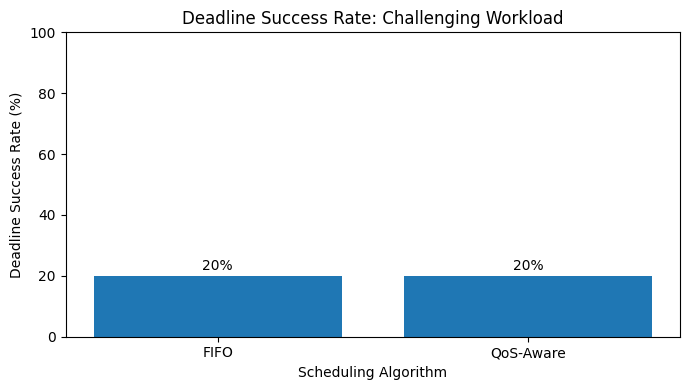

In [ ]:
import matplotlib.pyplot as plt

algorithms = challenging_comparison["Algorithm"]
success_rates = challenging_comparison["Deadline Success Rate (%)"]

plt.figure(figsize=(7, 4))
bars = plt.bar(algorithms, success_rates)

plt.title("Deadline Success Rate: Challenging Workload")
plt.xlabel("Scheduling Algorithm")
plt.ylabel("Deadline Success Rate (%)")
plt.ylim(0, 100)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 2,
        f"{height:.0f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [ ]:
# Calculate average deadline violation for each scheduler

def calculate_deadline_violation(results):
    violations = [
        max(0, result["completion_time"] - result["deadline"])
        for result in results
    ]
    return sum(violations) / len(violations)

fifo_avg_violation = calculate_deadline_violation(
    challenging_fifo_results
)

qos_avg_violation = calculate_deadline_violation(
    challenging_qos_results
)

violation_comparison = pd.DataFrame([
    {
        "Algorithm": "FIFO",
        "Average Deadline Violation": round(fifo_avg_violation, 2)
    },
    {
        "Algorithm": "QoS-Aware",
        "Average Deadline Violation": round(qos_avg_violation, 2)
    }
])

display(violation_comparison)

,Algorithm,Average Deadline Violation
0,FIFO,3.80
1,QoS-Aware,3.38


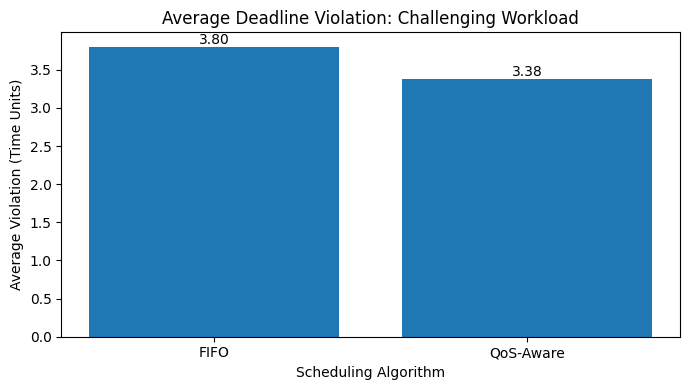

In [ ]:
import matplotlib.pyplot as plt

algorithms = ["FIFO", "QoS-Aware"]
violations = [fifo_avg_violation, qos_avg_violation]

plt.figure(figsize=(7, 4))
bars = plt.bar(algorithms, violations)

plt.title("Average Deadline Violation: Challenging Workload")
plt.xlabel("Scheduling Algorithm")
plt.ylabel("Average Violation (Time Units)")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [ ]:
# Final summary of the challenging-workload experiment

summary = pd.DataFrame([
    {
        "Metric": "Average completion time",
        "FIFO": round(
            sum(r["completion_time"] for r in challenging_fifo_results)
            / len(challenging_fifo_results), 2
        ),
        "QoS-Aware": round(
            sum(r["completion_time"] for r in challenging_qos_results)
            / len(challenging_qos_results), 2
        )
    },
    {
        "Metric": "Deadline misses",
        "FIFO": sum(
            r["missed_deadline"] for r in challenging_fifo_results
        ),
        "QoS-Aware": sum(
            r["missed_deadline"] for r in challenging_qos_results
        )
    },
    {
        "Metric": "Average deadline violation",
        "FIFO": round(fifo_avg_violation, 2),
        "QoS-Aware": round(qos_avg_violation, 2)
    }
])

display(summary)

,Metric,FIFO,QoS-Aware
0,Average completion time,7.61,7.18
1,Deadline misses,8.00,8.00
2,Average deadline violation,3.80,3.38


In [ ]:
# Define a reward function for a scheduling decision

def scheduling_reward(completion_time, deadline, priority):
    lateness = max(0, completion_time - deadline)

    reward = -completion_time - (5 * lateness) + (2 * priority)

    return round(reward, 2)


# Example decision using a task from the challenging workload
example_task = challenging_tasks[0]
example_node = edge_nodes[0]

example_processing_time = (
    example_task["execution_time"] / example_node["speed"]
)

example_completion_time = example_processing_time

example_reward = scheduling_reward(
    completion_time=example_completion_time,
    deadline=example_task["deadline"],
    priority=example_task["priority"]
)

print("Example task:", example_task["task_id"])
print("Example node:", example_node["node_id"])
print("Example completion time:", round(example_completion_time, 2))
print("Example scheduling reward:", example_reward)

Example task: 1
Example node: 1
Example completion time: 7.0
Example scheduling reward: -10.0


In [ ]:
# Define possible scheduling actions

actions = {
    0: 1,  # Action 0 selects Edge Node 1
    1: 2,  # Action 1 selects Edge Node 2
    2: 3   # Action 2 selects Edge Node 3
}

print("Available scheduling actions:")

for action, node_id in actions.items():
    print(f"Action {action} -> Edge Node {node_id}")

Available scheduling actions:
Action 0 -> Edge Node 1
Action 1 -> Edge Node 2
Action 2 -> Edge Node 3


In [ ]:
# Create local Q-tables for the three edge nodes

states = [
    (priority, urgency)
    for priority in [1, 2, 3]
    for urgency in [0, 1]
]

local_q_tables = {}

for node in edge_nodes:
    local_q_tables[node["node_id"]] = {
        state: {action: 0.0 for action in actions}
        for state in states
    }

print("Q-tables initialized!")

for node_id, q_table in local_q_tables.items():
    print(f"\nEdge Node {node_id}")
    print("Number of states:", len(q_table))
    print("Example state scores:", q_table[(1, 0)])

Q-tables initialized!

Edge Node 1
Number of states: 6
Example state scores: {0: 0.0, 1: 0.0, 2: 0.0}

Edge Node 2
Number of states: 6
Example state scores: {0: 0.0, 1: 0.0, 2: 0.0}

Edge Node 3
Number of states: 6
Example state scores: {0: 0.0, 1: 0.0, 2: 0.0}


In [ ]:
# Define the Q-learning update rule

def update_q_value(
    current_q,
    reward,
    next_state_best_q,
    learning_rate=0.1,
    discount_factor=0.9
):
    updated_q = current_q + learning_rate * (
        reward
        + discount_factor * next_state_best_q
        - current_q
    )

    return round(updated_q, 4)


# Test one update
old_q = 0.0
reward = 2.0
next_best_q = 1.0

new_q = update_q_value(old_q, reward, next_best_q)

print("Old Q-value:", old_q)
print("Reward:", reward)
print("Best next-state Q-value:", next_best_q)
print("Updated Q-value:", new_q)

Old Q-value: 0.0
Reward: 2.0
Best next-state Q-value: 1.0
Updated Q-value: 0.29


In [ ]:
# Simulate one local Q-learning update on each edge node

learning_rate = 0.1
discount_factor = 0.9

# Sample state, action, reward, and next state
state = (2, 1)
action = 1
reward = 2.0
next_state = (2, 0)

for node_id, q_table in local_q_tables.items():
    old_q = q_table[state][action]

    best_next_q = max(q_table[next_state].values())

    q_table[state][action] = update_q_value(
        current_q=old_q,
        reward=reward,
        next_state_best_q=best_next_q,
        learning_rate=learning_rate,
        discount_factor=discount_factor
    )

    print(
        f"Edge Node {node_id}: "
        f"updated Q-value = {q_table[state][action]}"
    )

Edge Node 1: updated Q-value = 0.2
Edge Node 2: updated Q-value = 0.2
Edge Node 3: updated Q-value = 0.2


In [ ]:
# Federated averaging of local Q-tables

global_q_table = {}

for state in states:
    global_q_table[state] = {}

    for action in actions:
        average_q = sum(
            local_q_tables[node_id][state][action]
            for node_id in local_q_tables
        ) / len(local_q_tables)

        global_q_table[state][action] = round(average_q, 4)

print("Global Q-table after federated averaging")
print("State (2, 1):", global_q_table[(2, 1)])

Global Q-table after federated averaging
State (2, 1): {0: 0.0, 1: 0.2, 2: 0.0}


In [ ]:
# Distribute the global Q-table to every edge node

for node_id in local_q_tables:
    local_q_tables[node_id] = {
        state: action_values.copy()
        for state, action_values in global_q_table.items()
    }

print("Q-tables after global model distribution:")

for node_id, q_table in local_q_tables.items():
    print(
        f"Edge Node {node_id}: "
        f"Q-values for state (2, 1) = {q_table[(2, 1)]}"
    )

Q-tables after global model distribution:
Edge Node 1: Q-values for state (2, 1) = {0: 0.0, 1: 0.2, 2: 0.0}
Edge Node 2: Q-values for state (2, 1) = {0: 0.0, 1: 0.2, 2: 0.0}
Edge Node 3: Q-values for state (2, 1) = {0: 0.0, 1: 0.2, 2: 0.0}


In [ ]:
# Select an edge node using the learned global Q-table

def choose_edge_node(state, q_table):
    best_action = max(
        q_table[state],
        key=q_table[state].get
    )

    return actions[best_action]


example_state = (2, 1)

selected_node = choose_edge_node(
    example_state,
    global_q_table
)

print("Task state:", example_state)
print("Learned action scores:", global_q_table[example_state])
print("Selected Edge Node:", selected_node)

Task state: (2, 1)
Learned action scores: {0: 0.0, 1: 0.2, 2: 0.0}
Selected Edge Node: 2


In [ ]:
# Test the current Q-table policy on the challenging workload

learned_node_times = {
    node["node_id"]: 0 for node in edge_nodes
}

learned_results = []

for task in challenging_tasks:
    urgency = 1 if task["deadline"] <= 5 else 0
    state = (task["priority"], urgency)

    selected_node_id = choose_edge_node(state, global_q_table)
    selected_node = next(
        node for node in edge_nodes
        if node["node_id"] == selected_node_id
    )

    processing_time = (
        task["execution_time"] / selected_node["speed"]
    )

    completion_time = (
        learned_node_times[selected_node_id] + processing_time
    )

    learned_node_times[selected_node_id] = completion_time

    learned_results.append({
        "task_id": task["task_id"],
        "priority": task["priority"],
        "node_id": selected_node_id,
        "completion_time": round(completion_time, 2),
        "deadline": task["deadline"],
        "missed_deadline": completion_time > task["deadline"]
    })

for result in learned_results:
    print(result)

{'task_id': 1, 'priority': 1, 'node_id': 1, 'completion_time': 7.0, 'deadline': 6, 'missed_deadline': True}
{'task_id': 2, 'priority': 2, 'node_id': 2, 'completion_time': 3.33, 'deadline': 2, 'missed_deadline': True}
{'task_id': 3, 'priority': 3, 'node_id': 1, 'completion_time': 14.5, 'deadline': 3, 'missed_deadline': True}
{'task_id': 4, 'priority': 1, 'node_id': 1, 'completion_time': 21.5, 'deadline': 4, 'missed_deadline': True}
{'task_id': 5, 'priority': 3, 'node_id': 1, 'completion_time': 27.5, 'deadline': 8, 'missed_deadline': True}
{'task_id': 6, 'priority': 2, 'node_id': 2, 'completion_time': 6.0, 'deadline': 5, 'missed_deadline': True}
{'task_id': 7, 'priority': 2, 'node_id': 2, 'completion_time': 8.0, 'deadline': 3, 'missed_deadline': True}
{'task_id': 8, 'priority': 1, 'node_id': 1, 'completion_time': 31.0, 'deadline': 5, 'missed_deadline': True}
{'task_id': 9, 'priority': 2, 'node_id': 2, 'completion_time': 12.33, 'deadline': 3, 'missed_deadline': True}
{'task_id': 10, 'prio

In [ ]:
# Evaluate the learned scheduling policy

learned_average_completion = sum(
    result["completion_time"] for result in learned_results
) / len(learned_results)

learned_deadline_misses = sum(
    result["missed_deadline"] for result in learned_results
)

learned_deadline_success = (
    (len(learned_results) - learned_deadline_misses)
    / len(learned_results)
) * 100

print("===== LEARNED SCHEDULER RESULTS =====")
print("Total tasks:", len(learned_results))
print(
    "Average completion time:",
    round(learned_average_completion, 2)
)
print("Deadline misses:", learned_deadline_misses)
print(
    "Deadline success rate:",
    round(learned_deadline_success, 2),
    "%"
)

===== LEARNED SCHEDULER RESULTS =====
Total tasks: 10
Average completion time: 14.75
Deadline misses: 10
Deadline success rate: 0.0 %


In [ ]:
# Compare all three schedulers on the challenging workload

all_scheduler_results = pd.DataFrame([
    {
        "Algorithm": "FIFO",
        "Average Completion Time": round(
            sum(r["completion_time"] for r in challenging_fifo_results)
            / len(challenging_fifo_results), 2
        ),
        "Deadline Misses": sum(
            r["missed_deadline"] for r in challenging_fifo_results
        )
    },
    {
        "Algorithm": "QoS-Aware",
        "Average Completion Time": round(
            sum(r["completion_time"] for r in challenging_qos_results)
            / len(challenging_qos_results), 2
        ),
        "Deadline Misses": sum(
            r["missed_deadline"] for r in challenging_qos_results
        )
    },
    {
        "Algorithm": "Q-Learning Prototype",
        "Average Completion Time": round(learned_average_completion, 2),
        "Deadline Misses": learned_deadline_misses
    }
])

all_scheduler_results["Deadline Success Rate (%)"] = (
    100 * (
        len(challenging_tasks) - all_scheduler_results["Deadline Misses"]
    ) / len(challenging_tasks)
).round(2)

display(all_scheduler_results)

,Algorithm,Average Completion Time,Deadline Misses,Deadline Success Rate (%)
0,FIFO,7.61,8,20.0
1,QoS-Aware,7.18,8,20.0
2,Q-Learning Prototype,14.75,10,0.0


In [ ]:
# Improved action selection with random tie-breaking

import random

def choose_edge_node(state, q_table):
    action_scores = q_table[state]
    best_score = max(action_scores.values())

    best_actions = [
        action for action, score in action_scores.items()
        if score == best_score
    ]

    chosen_action = random.choice(best_actions)

    return actions[chosen_action]


print("Updated action selection is ready!")
print("It randomly breaks ties between equally scored actions.")

Updated action selection is ready!
It randomly breaks ties between equally scored actions.


In [ ]:
# Rerun the learned scheduler with random tie-breaking

random.seed(42)

learned_node_times = {
    node["node_id"]: 0 for node in edge_nodes
}

learned_results = []

for task in challenging_tasks:
    urgency = 1 if task["deadline"] <= 5 else 0
    state = (task["priority"], urgency)

    selected_node_id = choose_edge_node(state, global_q_table)
    selected_node = next(
        node for node in edge_nodes
        if node["node_id"] == selected_node_id
    )

    processing_time = task["execution_time"] / selected_node["speed"]
    completion_time = (
        learned_node_times[selected_node_id] + processing_time
    )

    learned_node_times[selected_node_id] = completion_time

    learned_results.append({
        "task_id": task["task_id"],
        "priority": task["priority"],
        "node_id": selected_node_id,
        "completion_time": round(completion_time, 2),
        "deadline": task["deadline"],
        "missed_deadline": completion_time > task["deadline"]
    })

learned_average_completion = sum(
    r["completion_time"] for r in learned_results
) / len(learned_results)

learned_deadline_misses = sum(
    r["missed_deadline"] for r in learned_results
)

learned_deadline_success = (
    (len(learned_results) - learned_deadline_misses)
    / len(learned_results)
) * 100

print("Learned scheduler results")
print("Average completion time:", round(learned_average_completion, 2))
print("Deadline misses:", learned_deadline_misses)
print("Deadline success rate:", round(learned_deadline_success, 2), "%")
print("Node assignments:", [r["node_id"] for r in learned_results])

Learned scheduler results
Average completion time: 9.62
Deadline misses: 8
Deadline success rate: 20.0 %
Node assignments: [3, 2, 1, 3, 2, 2, 2, 1, 2, 2]


In [ ]:
import pandas as pd

def get_metrics(results):
    total = len(results)
    misses = sum(r["missed_deadline"] for r in results)
    return {
        "Average Completion Time": round(
            sum(r["completion_time"] for r in results) / total, 2
        ),
        "Deadline Misses": misses,
        "Deadline Success (%)": round(
            (total - misses) / total * 100, 2
        )
    }

all_scheduler_results = pd.DataFrame([
    {"Scheduler": "FIFO", **get_metrics(challenging_fifo_results)},
    {"Scheduler": "QoS-Aware", **get_metrics(challenging_qos_results)},
    {"Scheduler": "Q-Learning Prototype", **get_metrics(learned_results)}
])

display(all_scheduler_results)

,Scheduler,Average Completion Time,Deadline Misses,Deadline Success (%)
0,FIFO,7.61,8,20.0
1,QoS-Aware,7.18,8,20.0
2,Q-Learning Prototype,9.62,8,20.0


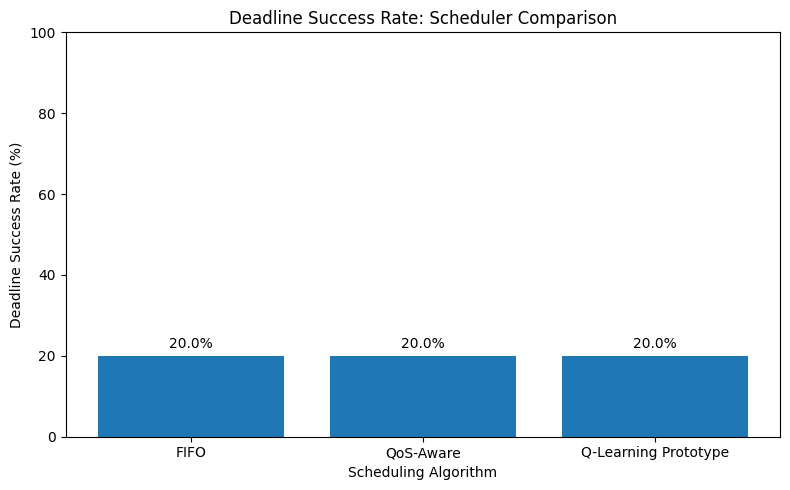

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    all_scheduler_results["Scheduler"],
    all_scheduler_results["Deadline Success (%)"]
)

plt.title("Deadline Success Rate: Scheduler Comparison")
plt.xlabel("Scheduling Algorithm")
plt.ylabel("Deadline Success Rate (%)")
plt.ylim(0, 100)

for i, value in enumerate(
    all_scheduler_results["Deadline Success (%)"]
):
    plt.text(i, value + 2, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

In [ ]:
def average_violation(results):
    return round(
        sum(
            max(0, r["completion_time"] - r["deadline"])
            for r in results
        ) / len(results),
        2
    )

violation_comparison = pd.DataFrame([
    {
        "Scheduler": "FIFO",
        "Average Deadline Violation": average_violation(
            challenging_fifo_results
        )
    },
    {
        "Scheduler": "QoS-Aware",
        "Average Deadline Violation": average_violation(
            challenging_qos_results
        )
    },
    {
        "Scheduler": "Q-Learning Prototype",
        "Average Deadline Violation": average_violation(
            learned_results
        )
    }
])

display(violation_comparison)

,Scheduler,Average Deadline Violation
0,FIFO,3.80
1,QoS-Aware,3.38
2,Q-Learning Prototype,5.81


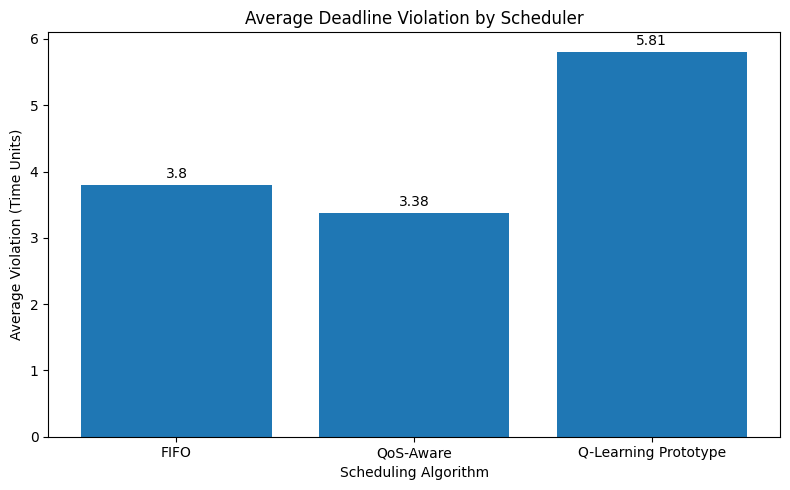

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    violation_comparison["Scheduler"],
    violation_comparison["Average Deadline Violation"]
)

plt.title("Average Deadline Violation by Scheduler")
plt.xlabel("Scheduling Algorithm")
plt.ylabel("Average Violation (Time Units)")

for i, value in enumerate(
    violation_comparison["Average Deadline Violation"]
):
    plt.text(i, value + 0.1, str(value), ha="center")

plt.tight_layout()
plt.show()

In [ ]:
all_scheduler_results.to_csv(
    "scheduler_comparison.csv",
    index=False
)

violation_comparison.to_csv(
    "deadline_violation_comparison.csv",
    index=False
)

print("Both comparison tables have been saved!")
print("1. scheduler_comparison.csv")
print("2. deadline_violation_comparison.csv")

Both comparison tables have been saved!
1. scheduler_comparison.csv
2. deadline_violation_comparison.csv


In [ ]:
from google.colab import files

all_scheduler_results.to_csv(
    "scheduler_comparison.csv", index=False
)
violation_comparison.to_csv(
    "deadline_violation_comparison.csv", index=False
)

files.download("scheduler_comparison.csv")
files.download("deadline_violation_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import random
import pandas as pd

def run_ablation(seed=101):
    random.seed(seed)

    # Generate the challenging workload
    tasks = []
    for i in range(10):
        tasks.append({
            "task_id": i,
            "execution_time": random.randint(5, 15),
            "priority": random.randint(1, 3),
            "deadline": random.randint(2, 8)
        })

    nodes = {"Node 1": 2, "Node 2": 3, "Node 3": 5}

    def simulate(task_list):
        node_available = {node: 0.0 for node in nodes}
        completion_times = []
        violations = []

        for task in task_list:
            # Assign the task to the node with earliest finish
            choices = {
                node: node_available[node]
                      + task["execution_time"] / speed
                for node, speed in nodes.items()
            }
            selected_node = min(choices, key=choices.get)
            completion = choices[selected_node]
            node_available[selected_node] = completion

            completion_times.append(completion)
            violations.append(
                max(0, completion - task["deadline"])
            )

        misses = sum(v > 0 for v in violations)

        return {
            "Average completion time": round(
                sum(completion_times) / len(task_list), 2
            ),
            "Deadline misses": misses,
            "Deadline success rate (%)": round(
                100 * (len(task_list) - misses) / len(task_list), 2
            ),
            "Average deadline violation": round(
                sum(violations) / len(task_list), 2
            )
        }

    # Full QoS heuristic: priority first, then earliest deadline
    full_qos = sorted(
        tasks,
        key=lambda t: (-t["priority"], t["deadline"])
    )

    # Ablation: remove priority ordering; use deadline only
    without_priority = sorted(
        tasks,
        key=lambda t: t["deadline"]
    )

    results = pd.DataFrame({
        "Full QoS heuristic": simulate(full_qos),
        "Without priority ordering": simulate(without_priority)
    }).T

    print("Ablation study — challenging workload")
    display(results)
    return results

ablation_results = run_ablation()

Ablation study — challenging workload


,Average completion time,Deadline misses,Deadline success rate (%),Average deadline violation
Full QoS heuristic,7.18,8.0,20.0,3.38
Without priority ordering,7.09,8.0,20.0,2.89
